# Analisis Smoke Test

Bagian paling atas ini khusus untuk membaca hasil smoke test dari `results/smoke/`. Smoke test menjalankan satu seed, satu kondisi (`dlow_llow`), dan sejumlah pesan kecil untuk memastikan alur pengiriman serta pencatatan hasil berjalan. Gunakan hasil ini sebagai pemeriksaan awal, **bukan** sebagai bukti statistik atau kesimpulan bahwa satu skema lebih unggul.

Semua tabel dan grafik hanya ditampilkan di notebook. Cell ini tidak mengubah CSV hasil maupun menyimpan output ke direktori eksperimen.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SMOKE_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "results" / "smoke").is_dir()),
    None,
)
if SMOKE_ROOT is None:
    raise FileNotFoundError("Folder results/smoke tidak ditemukan dari lokasi notebook.")

smoke_dir = SMOKE_ROOT / "results" / "smoke"
smoke_messages = pd.read_csv(smoke_dir / "messages.csv")
smoke_runs = pd.read_csv(smoke_dir / "runs.csv")

required_message_columns = {
    "run_id", "scenario", "protocol", "acked", "success", "latency_ms"
}
required_run_columns = {
    "run_id", "scenario", "condition", "seed", "n_sent", "n_recv",
    "payload_bytes_total", "wire_total", "duration_s"
}
missing_messages = required_message_columns - set(smoke_messages.columns)
missing_runs = required_run_columns - set(smoke_runs.columns)
if missing_messages or missing_runs:
    raise ValueError(
        f"Kolom smoke CSV tidak sesuai. messages={sorted(missing_messages)}, "
        f"runs={sorted(missing_runs)}"
    )

smoke_messages["latency_ms"] = pd.to_numeric(
    smoke_messages["latency_ms"], errors="coerce"
)
print(
    f"Folder hasil: {smoke_dir} | {len(smoke_runs)} run | "
    f"{len(smoke_messages)} pesan tercatat"
)
display(smoke_runs[["scenario", "condition", "seed", "n_sent", "n_recv", "duration_s"]])

Folder hasil: e:\Naqiyyah\Codingan\CodinganSemester7\Skrispi\adaptive-protocol-selection-simulation\results\smoke | 3 run | 180 pesan tercatat


,scenario,condition,seed,n_sent,n_recv,duration_s
0,mqtt_qos1,dlow_llow,1,60,60,2.7
1,coap_con,dlow_llow,1,60,60,4.5
2,adaptive,dlow_llow,1,60,60,4.5


## Ringkasan smoke test

PDR dihitung dari jumlah penerimaan collector dibagi jumlah pesan terkirim. Mean dan p95 latency hanya memakai pesan yang diterima; baca keduanya bersama PDR. Overhead mengikuti definisi proyek dan memakai estimasi byte dari injector.

In [2]:
smoke_latency = smoke_messages.groupby("run_id")["latency_ms"].agg(
    latency_mean_ms="mean",
    latency_p95_ms=lambda values: values.quantile(0.95),
)
smoke_summary = smoke_runs.set_index("run_id").join(smoke_latency).reset_index()
smoke_summary["pdr_pct"] = (
    100 * smoke_summary["n_recv"] / smoke_summary["n_sent"].replace(0, np.nan)
)
smoke_summary["overhead_pct"] = (
    100 * (smoke_summary["wire_total"] - smoke_summary["payload_bytes_total"])
    / smoke_summary["wire_total"].replace(0, np.nan)
)
smoke_summary["bytes_per_delivered"] = (
    smoke_summary["wire_total"] / smoke_summary["n_recv"].replace(0, np.nan)
)

smoke_metrics = [
    "pdr_pct", "latency_mean_ms", "latency_p95_ms",
    "overhead_pct", "bytes_per_delivered",
]
display(smoke_summary[["scenario", "condition", "seed", "n_sent", "n_recv", *smoke_metrics]].round(2))

,scenario,condition,seed,n_sent,n_recv,pdr_pct,latency_mean_ms,latency_p95_ms,overhead_pct,bytes_per_delivered
0,mqtt_qos1,dlow_llow,1,60,60,100.0,113.29,710.51,63.10,187.63
1,coap_con,dlow_llow,1,60,60,100.0,203.47,469.91,53.79,149.82
2,adaptive,dlow_llow,1,60,60,100.0,199.23,956.90,61.42,179.43


## Keputusan adaptive dan grafik ringkas

Distribusi keputusan memperlihatkan protokol yang dipilih adaptive selama smoke test. Grafik metrik hanya memudahkan pemeriksaan cepat; jumlah run dan seed smoke test tidak cukup untuk menyimpulkan keunggulan statistik.

,jumlah_pesan,persentase
protocol,,
mqtt_qos1,52,86.7
coap_con,8,13.3


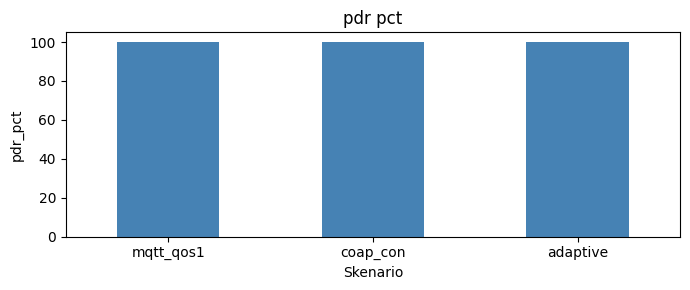

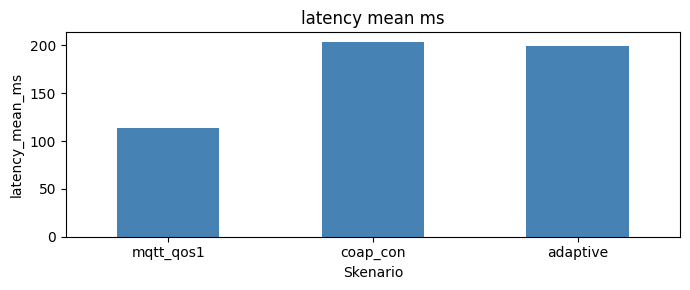

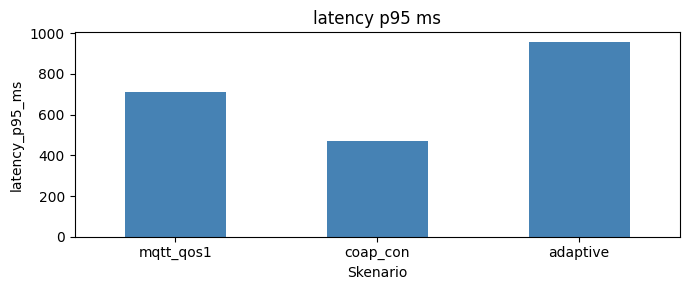

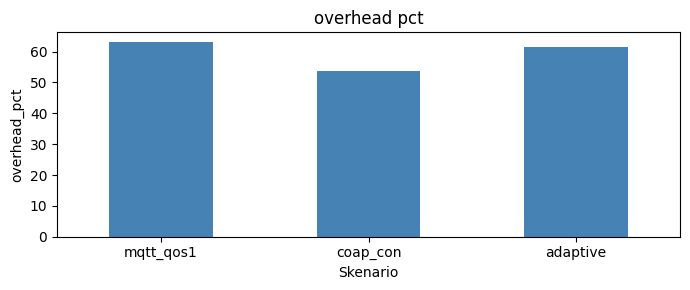

In [3]:
smoke_adaptive = smoke_messages.loc[smoke_messages["scenario"] == "adaptive"]
if smoke_adaptive.empty:
    print("Tidak ada skenario adaptive pada hasil smoke.")
else:
    decision_counts = smoke_adaptive["protocol"].value_counts().rename("jumlah_pesan")
    decision_pct = (100 * decision_counts / decision_counts.sum()).rename("persentase")
    display(pd.concat([decision_counts, decision_pct], axis=1).round(1))

scenario_order = [
    scenario for scenario in ["mqtt_qos1", "coap_con", "adaptive"]
    if scenario in set(smoke_summary["scenario"])
]
for metric in ["pdr_pct", "latency_mean_ms", "latency_p95_ms", "overhead_pct"]:
    values = smoke_summary.set_index("scenario").reindex(scenario_order)[metric]
    ax = values.plot.bar(figsize=(7, 3), color="steelblue")
    ax.set_title(metric.replace("_", " "))
    ax.set_xlabel("Skenario")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()

# Analisis Hasil Eksperimen

Notebook ini menganalisis file `messages.csv` dan `runs.csv` dari folder hasil proyek. Tabel dan grafik ditampilkan di notebook; file hasil eksperimen tidak diubah dan grafik tidak disimpan ke disk.

**Interpretasi metrik:** mean dan p95 latency dihitung hanya dari pesan yang diterima collector (success-only), sehingga selalu dibaca bersama PDR. `overhead_pct` dan `bytes_per_delivered` menggunakan byte wire estimasi dari injector, bukan packet capture.

In [4]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "results").is_dir() and (path / "simulation").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Jalankan notebook dari folder proyek atau salah satu subfoldernya.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from analysis.metrics import category_metrics, run_metrics

print(f"Folder proyek: {PROJECT_ROOT}")

Folder proyek: e:\Naqiyyah\Codingan\CodinganSemester7\Skrispi\adaptive-protocol-selection-simulation


## Pilih hasil eksperimen

Ubah `MODE` menjadi `comparative`, `characterization`, atau `smoke`. Mode `comparative` adalah pilihan awal untuk membandingkan adaptive, MQTT QoS 1, dan CoAP CON.

In [5]:
MODE = "comparative"  # comparative | characterization | smoke
AVAILABLE_MODES = {"comparative", "characterization", "smoke"}
if MODE not in AVAILABLE_MODES:
    raise ValueError(f"MODE harus salah satu dari {sorted(AVAILABLE_MODES)}")

RESULTS_DIR = PROJECT_ROOT / "results" / MODE
messages = pd.read_csv(RESULTS_DIR / "messages.csv")
runs = pd.read_csv(RESULTS_DIR / "runs.csv")

required_message_columns = {
    "run_id", "scenario", "condition", "seed", "category", "protocol",
    "acked", "success", "latency_ms",
}
required_run_columns = {
    "run_id", "scenario", "condition", "seed", "n_sent", "n_recv",
    "payload_bytes_total", "wire_total",
}
missing_messages = required_message_columns - set(messages.columns)
missing_runs = required_run_columns - set(runs.columns)
if missing_messages or missing_runs:
    raise ValueError(
        f"Kolom CSV tidak sesuai. messages={sorted(missing_messages)}, "
        f"runs={sorted(missing_runs)}"
    )

messages["latency_ms"] = pd.to_numeric(messages["latency_ms"], errors="coerce")
metrics = run_metrics(messages, runs)
messages_by_run = messages.drop(columns="condition").merge(
    runs[["run_id", "condition"]], on="run_id", validate="many_to_one"
)
print(f"Mode: {MODE} | {len(runs):,} run | {len(messages):,} baris pesan")
display(runs.groupby("scenario").size().rename("jumlah_run").to_frame())

Mode: comparative | 150 run | 90,000 baris pesan


,jumlah_run
scenario,
adaptive,50
coap_con,50
mqtt_qos1,50


## Ringkasan metrik per kondisi

Nilai ditampilkan sebagai rerata dan simpangan baku antar-run untuk tiap kondisi dan skenario.

In [6]:
METRICS = [
    "pdr_pct", "latency_mean", "latency_p95",
    "overhead_pct", "bytes_per_delivered",
]
summary = metrics.groupby(["condition", "scenario"])[METRICS].agg(["mean", "std"])
display(summary.round(2))

pdr_pct       latency_mean          latency_p95  \
                             mean   std         mean      std        mean   
condition       scenario                                                    
dhigh_lhigh     adaptive   100.00  0.00      4551.94   767.46    14226.48   
                coap_con    99.80  0.07      1196.91   371.12     4720.36   
                mqtt_qos1  100.00  0.00      5142.23  2361.67    18154.34   
dhigh_llow      adaptive   100.00  0.00       512.71    64.63     1230.93   
                coap_con   100.00  0.00       209.33    24.34      197.37   
                mqtt_qos1  100.00  0.00       325.41   113.54     1218.65   
dhigh_lmedium   adaptive   100.00  0.00      1077.95   160.60     3280.45   
                coap_con   100.00  0.00       505.34    97.32     2776.37   
                mqtt_qos1  100.00  0.00      1080.80   236.30     3548.40   
dlow_lhigh      adaptive   100.00  0.00      4282.83   535.91    16383.79   
                coap_con    99.90  0.15      1050.50   297.73     4571.12   
                mqtt_qos1  100.00  0.00      5468.66  1767.53    22468.23   
dlow_llow       adaptive   100.00  0.00       411.96    52.01     1072.48   
                coap_con   100.00  0.00        78.67    29.15       42.11   
                mqtt_qos1  100.00  0.00       249.89   148.45     1512.25   
dlow_lmedium    adaptive   100.00  0.00       977.82   277.62     2820.95   
                coap_con   100.00  0.00       370.30    60.56     2552.38   
                mqtt_qos1  100.00  0.00       795.02   223.76     2545.22   
dmedium_lhigh   adaptive   100.00  0.00      4231.62   479.16    16724.57   
                coap_con    99.90  0.09      1111.35   352.41     4855.54   
                mqtt_qos1  100.00  0.00      4114.97   990.83    15356.09   
dmedium_llow    adaptive   100.00  0.00       421.94    75.05     1105.24   
                coap_con   100.00  0.00       148.14    28.84      123.07   
                mqtt_qos1  100.00  0.00       291.00   185.17     1550.30   
dmedium_lmedium adaptive   100.00  0.00      1026.62   297.82     2838.60   
                coap_con    99.97  0.07       429.76    71.10     2694.03   
                mqtt_qos1  100.00  0.00      1097.43   274.44     5283.57   
dynamic         adaptive   100.00  0.00      2448.35   502.99    14173.84   
                coap_con   100.00  0.00       435.65    96.17     2620.68   
                mqtt_qos1  100.00  0.00      1871.34   678.00     8871.26   

                                    overhead_pct       bytes_per_delivered  \
                                std         mean   std                mean   
condition       scenario                                                     
dhigh_lhigh     adaptive    1402.78        69.02  0.98              224.72   
                coap_con    2253.50        68.91  1.65              224.75   
                mqtt_qos1  10126.40        70.09  0.83              232.76   
dhigh_llow      adaptive     103.69        60.98  0.19              178.28   
                coap_con       6.57        53.65  0.74              150.12   
                mqtt_qos1    529.62        62.80  0.19              187.03   
dhigh_lmedium   adaptive     944.90        62.68  0.82              186.50   
                coap_con     132.45        60.30  1.11              175.34   
                mqtt_qos1   1443.91        65.63  0.40              202.40   
dlow_lhigh      adaptive    6484.82        68.10  1.18              218.33   
                coap_con    2270.37        69.06  1.62              225.61   
                mqtt_qos1   7445.43        70.06  0.78              232.46   
dlow_llow       adaptive      80.15        60.47  0.26              176.00   
                coap_con       6.13        53.67  0.69              150.17   
                mqtt_qos1   1321.24        62.63  0.25              186.18   
dlow_lmedium    adaptive     770.29        62.43  0.75              185.23   
  

## Adaptive dibanding baseline

Delta dihitung dengan pasangan `condition` dan `seed` yang sama. Delta positif berarti angka metrik naik; untuk latency, overhead, dan byte per pesan, nilai yang lebih rendah umumnya lebih baik. Baris dengan pembagi nol tidak menghasilkan delta persentase.

In [7]:
def paired_delta(frame, baseline, test="adaptive", group_columns=("condition",)):
    if test not in set(frame["scenario"]) or baseline not in set(frame["scenario"]):
        return pd.DataFrame()

    index_columns = [*group_columns, "seed"]
    test_values = frame.loc[frame.scenario == test].set_index(index_columns)[METRICS]
    base_values = frame.loc[frame.scenario == baseline].set_index(index_columns)[METRICS]
    paired = test_values.join(base_values, how="inner", lsuffix="_test", rsuffix="_base")

    outputs = []
    for metric in METRICS:
        denominator = paired[f"{metric}_base"].replace(0, np.nan)
        delta_pct = 100 * (paired[f"{metric}_test"] - paired[f"{metric}_base"]) / denominator
        delta_frame = delta_pct.rename("delta_pct").reset_index()
        grouped = delta_frame.groupby(list(group_columns), dropna=False)["delta_pct"].agg(
            delta_mean="mean", delta_std="std", n="count"
        ).reset_index()
        grouped["metric"] = metric
        outputs.append(grouped)

    return pd.concat(outputs, ignore_index=True)

for baseline in ("mqtt_qos1", "coap_con"):
    comparison = paired_delta(metrics, baseline)
    if comparison.empty:
        print(f"Tidak tersedia pasangan adaptive vs {baseline} untuk mode {MODE}.")
    else:
        print(f"Adaptive dibanding {baseline} — delta persen per kondisi")
        display(comparison.round(2))

Adaptive dibanding mqtt_qos1 — delta persen per kondisi


,condition,delta_mean,delta_std,n,metric
0,dhigh_lhigh,0.00,0.00,5,pdr_pct
1,dhigh_llow,0.00,0.00,5,pdr_pct
2,dhigh_lmedium,0.00,0.00,5,pdr_pct
3,dlow_lhigh,0.00,0.00,5,pdr_pct
4,dlow_llow,0.00,0.00,5,pdr_pct
5,dlow_lmedium,0.00,0.00,5,pdr_pct
6,dmedium_lhigh,0.00,0.00,5,pdr_pct
7,dmedium_llow,0.00,0.00,5,pdr_pct
8,dmedium_lmedium,0.00,0.00,5,pdr_pct
9,dynamic,0.00,0.00,5,pdr_pct


Adaptive dibanding coap_con — delta persen per kondisi


,condition,delta_mean,delta_std,n,metric
0,dhigh_lhigh,0.20,0.07,5,pdr_pct
1,dhigh_llow,0.00,0.00,5,pdr_pct
2,dhigh_lmedium,0.00,0.00,5,pdr_pct
3,dlow_lhigh,0.10,0.15,5,pdr_pct
4,dlow_llow,0.00,0.00,5,pdr_pct
5,dlow_lmedium,0.00,0.00,5,pdr_pct
6,dmedium_lhigh,0.10,0.09,5,pdr_pct
7,dmedium_llow,0.00,0.00,5,pdr_pct
8,dmedium_lmedium,0.03,0.07,5,pdr_pct
9,dynamic,0.00,0.00,5,pdr_pct


## Kinerja menurut kategori PM2.5

Tabel ini melaporkan PDR dan latency success-only per kategori. Kondisi untuk run dinamis diperlakukan sebagai satu kondisi `dynamic`, sesuai analisis proyek.

In [8]:
by_category = category_metrics(messages, runs)
category_summary = by_category.groupby(["condition", "scenario", "category"])[
    ["pdr_pct", "latency_mean", "latency_p95"]
].agg(["mean", "std"])
display(category_summary.round(2))

pdr_pct       latency_mean           \
                                  mean   std         mean      std   
condition   scenario  category                                       
dhigh_lhigh adaptive  critical   100.0  0.00      4145.33  1232.65   
                      normal     100.0  0.00      5166.50  1879.24   
                      warning    100.0  0.00      4344.00   744.94   
            coap_con  critical    99.9  0.22      1083.70   158.16   
                      normal      99.8  0.27      1225.35   560.81   
...                                ...   ...          ...      ...   
dynamic     coap_con  normal     100.0  0.00       441.98   160.50   
                      warning    100.0  0.00       423.76   120.74   
            mqtt_qos1 critical   100.0  0.00      1941.58  1369.47   
                      normal     100.0  0.00      1768.88  1286.85   
                      warning    100.0  0.00      1903.57   791.02   

                               latency_p95           
                                      mean      std  
condition   scenario  category                       
dhigh_lhigh adaptive  critical    13835.61   645.95  
                      normal      16972.07  7556.45  
                      warning     13229.93  2098.93  
            coap_con  critical     3830.25  1606.90  
                      normal       5381.97  2263.53  
...                                    ...      ...  
dynamic     coap_con  normal       2585.14   265.83  
                      warning      2518.90   119.24  
            mqtt_qos1 critical     6853.25  5617.78  
                      normal       6012.12  4670.01  
                      warning      7968.17  5439.71  

[90 rows x 6 columns]

## Distribusi pilihan protokol adaptive

Distribusi keputusan bukan metrik keberhasilan pengiriman. Cell akan memberi pesan jika mode yang dipilih tidak memiliki skenario adaptive.

Persentase pilihan protokol menurut kategori


protocol,coap_con,mqtt_qos1
category,,
critical,0.3,99.7
normal,6.8,93.2
warning,2.9,97.1


Persentase pilihan protokol menurut kondisi


protocol,coap_con,mqtt_qos1
condition,,
dhigh_lhigh,0.0,100.0
dhigh_llow,0.0,100.0
dhigh_lmedium,0.0,100.0
dlow_lhigh,3.8,96.2
dlow_llow,8.6,91.4
dlow_lmedium,8.1,91.9
dmedium_lhigh,2.6,97.4
dmedium_llow,4.5,95.5
dmedium_lmedium,3.6,96.4


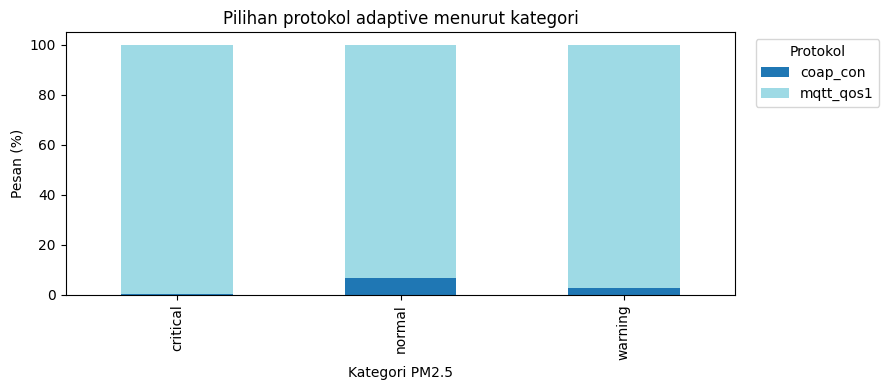

In [9]:
adaptive_messages = messages_by_run.loc[messages_by_run.scenario == "adaptive"]
if adaptive_messages.empty:
    print(f"Tidak ada pesan adaptive di mode {MODE}.")
else:
    by_category_protocol = pd.crosstab(
        adaptive_messages.category,
        adaptive_messages.protocol,
        normalize="index",
    ) * 100
    by_condition_protocol = pd.crosstab(
        adaptive_messages.condition,
        adaptive_messages.protocol,
        normalize="index",
    ) * 100
    print("Persentase pilihan protokol menurut kategori")
    display(by_category_protocol.round(1))
    print("Persentase pilihan protokol menurut kondisi")
    display(by_condition_protocol.round(1))

    ax = by_category_protocol.plot.bar(stacked=True, figsize=(9, 4), colormap="tab20")
    ax.set_ylabel("Pesan (%)")
    ax.set_xlabel("Kategori PM2.5")
    ax.set_title("Pilihan protokol adaptive menurut kategori")
    ax.legend(title="Protokol", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Grafik metrik per kondisi

Grafik menggunakan nilai rata-rata antar-run. Gunakan tabel di atas untuk melihat simpangan baku dan jumlah run.

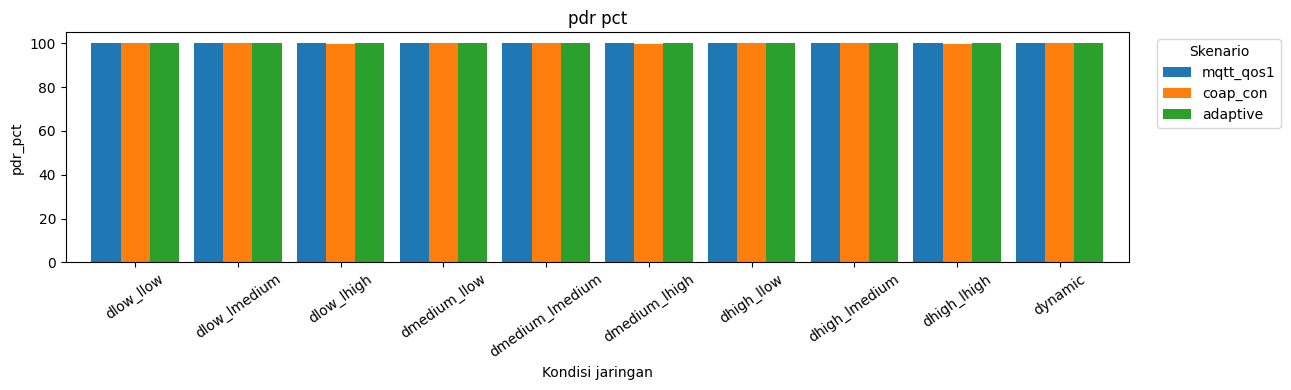

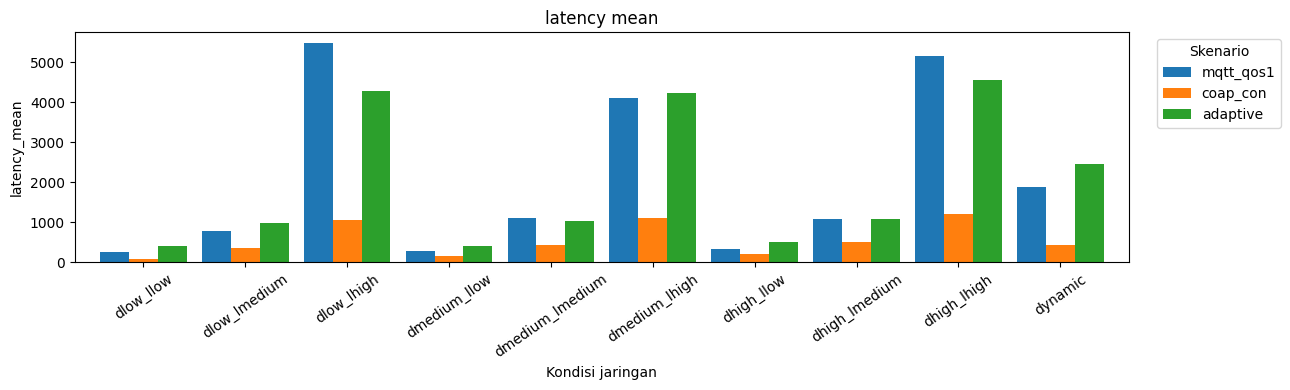

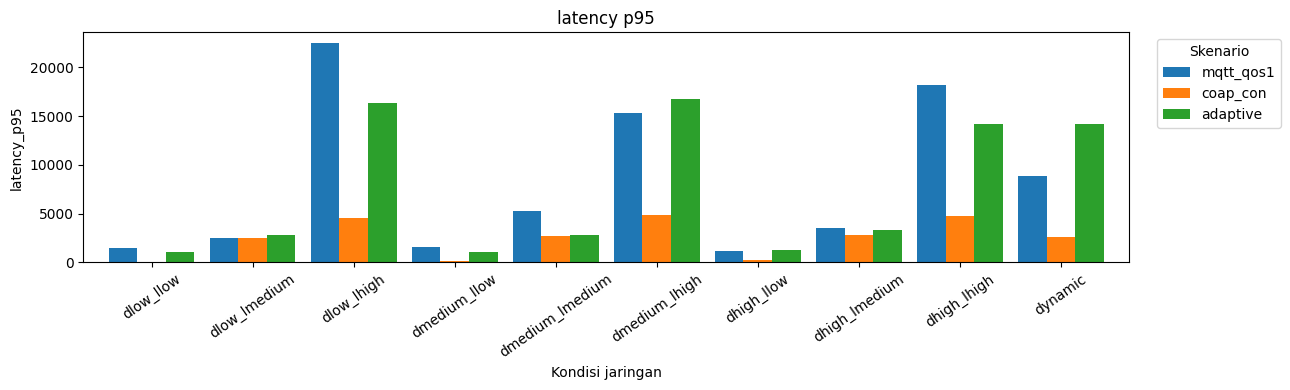

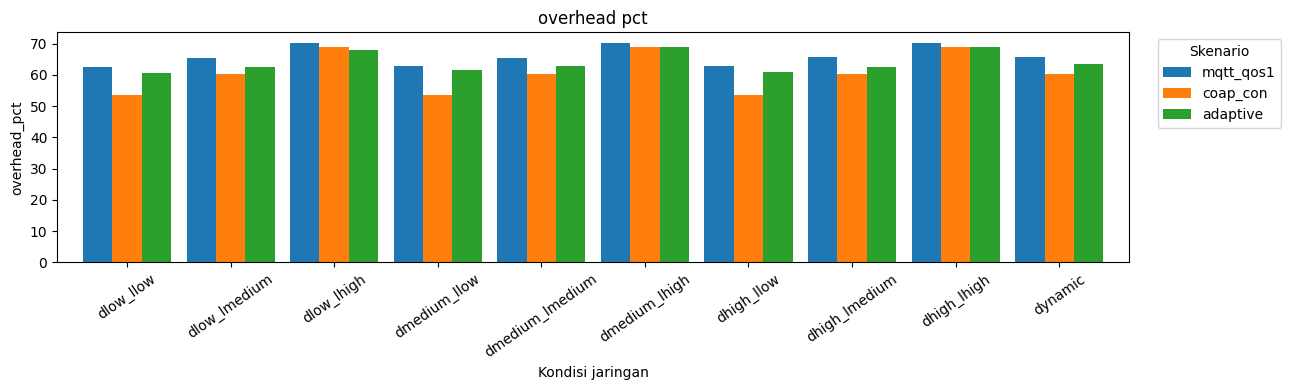

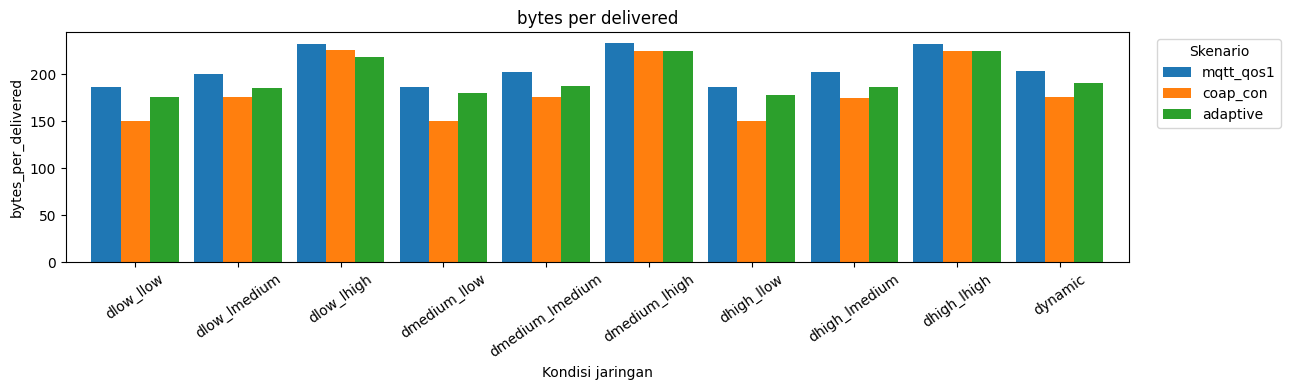

In [10]:
scenario_preference = [
    "mqtt_qos1", "coap_con", "adaptive", "mqtt_qos2", "mqtt_qos0", "coap_non"
]
scenario_order = [s for s in scenario_preference if s in set(metrics.scenario)]
condition_preference = [
    "dlow_llow", "dlow_lmedium", "dlow_lhigh",
    "dmedium_llow", "dmedium_lmedium", "dmedium_lhigh",
    "dhigh_llow", "dhigh_lmedium", "dhigh_lhigh", "dynamic",
]
condition_order = [c for c in condition_preference if c in set(metrics.condition)]

for metric in METRICS:
    means = metrics.groupby(["condition", "scenario"])[metric].mean().unstack("scenario")
    means = means.reindex(index=condition_order, columns=scenario_order)
    ax = means.plot.bar(figsize=(13, 4), width=0.85)
    ax.set_title(metric.replace("_", " "))
    ax.set_xlabel("Kondisi jaringan")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Skenario", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## Latency dan konsistensi ACK

Latency pada boxplot hanya mencakup pesan yang diterima collector. Tabel ACK membedakan konfirmasi protokol dari keberhasilan pesan mencapai collector.

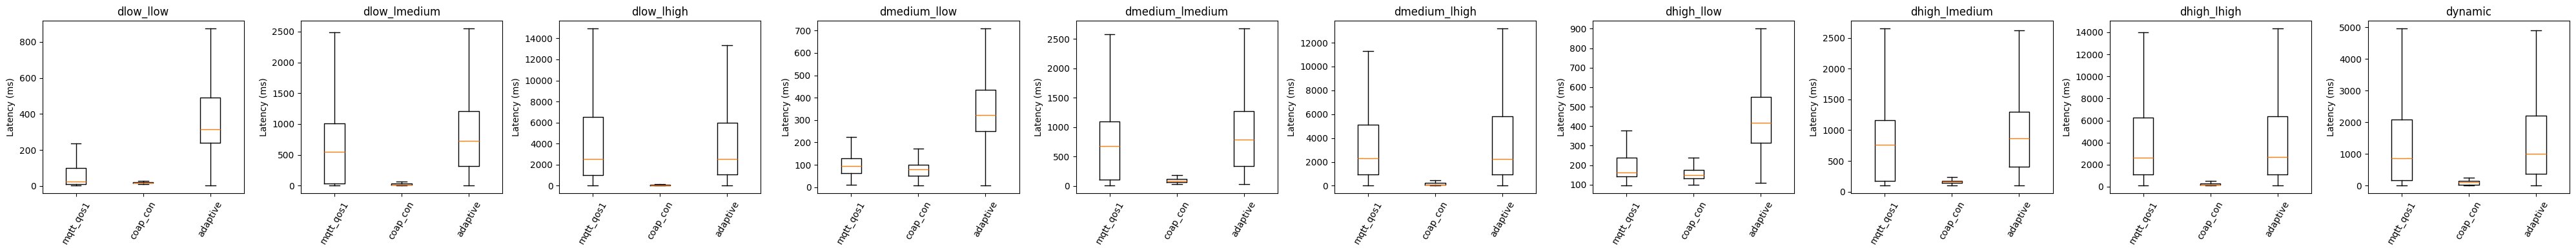

,scenario,acked,success,jumlah_pesan
0,adaptive,0,1,1
1,adaptive,1,1,29999
2,coap_con,0,0,13
3,coap_con,0,1,132
4,coap_con,1,1,29855
5,mqtt_qos1,1,1,30000


,jumlah_pesan,latency_tidak_tersedia,latency_tersedia_pct
scenario,,,
adaptive,30000,0,100.00
coap_con,30000,13,99.96
mqtt_qos1,30000,0,100.00


In [11]:
successful = messages_by_run.loc[messages_by_run.latency_ms.notna()]
available_conditions = [c for c in condition_order if c in set(successful.condition)]
if available_conditions:
    fig, axes = plt.subplots(
        1, len(available_conditions),
        figsize=(max(6, 4 * len(available_conditions)), 4),
        squeeze=False,
    )
    for ax, condition in zip(axes[0], available_conditions):
        subset = successful.loc[successful.condition == condition]
        values = [subset.loc[subset.scenario == scenario, "latency_ms"].dropna()
                  for scenario in scenario_order]
        ax.boxplot(values, tick_labels=scenario_order, showfliers=False)
        ax.set_title(condition)
        ax.tick_params(axis="x", rotation=60)
        ax.set_ylabel("Latency (ms)")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada observasi latency yang tersedia untuk digrafikkan.")

ack_summary = messages.groupby(["scenario", "acked", "success"], dropna=False).size()
display(ack_summary.rename("jumlah_pesan").reset_index())

latency_coverage = messages.groupby("scenario").agg(
    jumlah_pesan=("run_id", "size"),
    latency_tidak_tersedia=("latency_ms", lambda values: values.isna().sum()),
)
latency_coverage["latency_tersedia_pct"] = 100 * (
    1 - latency_coverage["latency_tidak_tersedia"] / latency_coverage["jumlah_pesan"]
)
display(latency_coverage.round(2))